Calculating polarizability of 1S0 and 3PO under 399 blue imaging light and also
under 460 tweezers.

States:
1S0 and 3P0 (plus 3P1 for 556 nm imaging)

Light:
- 460.862 nm tweezers: the clock array, and the imaging array for 399 nm imaging
- 780 nm tweezers: the imaging array for 556 nm imaging
- 399 nm or 556 nm imaging light nearby

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import scipy.constants
from sympy.physics.wigner import wigner_6j

""" 
constants
"""
pi = np.pi
c = sp.constants.c
epsilon_0 = sp.constants.epsilon_0
hbar = sp.constants.hbar
h = sp.constants.h
dm_au = sp.constants.physical_constants["atomic unit of electric dipole mom."][0]
t_au = sp.constants.physical_constants["atomic unit of time"][0]


# α/h [Hz/(V/m)2]=2.48832×10−8 α [a.u.] from https://arxiv.org/pdf/1507.06570.pdf
# α [a.u.] = 1.648 777 274 36 x 10-41 α [C2 m2 J-1] #https://physics.nist.gov/cgi-bin/cuu/Value?auepol
alpha_au = 1.64877727436*1e-41

We are going to ignore vector light transitions for now. 

And I think we can neglect tensor polarizability because F = 1/2.

So I will start by just calculating the scalar polarizabities of each of our states.

In [2]:
class state(object):
    def __init__(self, L, S, J):
        '''State for which we are calculating the polarizability or light shift.'''
        self.L = L
        self.S = S
        self.J = J

In [3]:
class transition(object):
    def __init__(self, WN, Gamma, J): 
        '''wavenumber of transition in cm-1; decay rate in MHz; J of final state'''
        self.omega = 2 * np.pi * c * WN * 1e2 #transition freq in rad/s
        self.Gamma = 2 * np.pi * Gamma * 1e6 #decay rate in rad/s
        self.J = J #J of final state

Reduced matrix element:
$$
| \langle {J}||\mathbf{d}|| {J'} \rangle | = \sqrt{\frac{3\pi\epsilon_0\hbar c^3 }
{\omega_{J'J}^3 } \frac{2J' +1}{2J+1}\Gamma_{J'J} }
$$


In [4]:
def dm(transition, state):
    '''Reduced matrix element for a transition between J->J' states '''
    return np.sqrt( 
            3*np.pi * epsilon_0 * hbar * c**3 / transition.omega**3 
            * (2*transition.J + 1) / (2*state.J + 1) * transition.Gamma 
           )

Polarizability:
$$\alpha_J(\omega) = \sum_{n'J'}\frac{2\omega_{n'J'J}| \langle {J}||\mathbf{d}|| {J'} \rangle |^2}{3\hbar(\omega_{n'J'J}^2-\omega^2)}$$

In [5]:
def alpha(transitions, state): #polarizability
    return lambda omega: sum(
        [2*t.omega*(dm(t, state))**2 / 3 / hbar / (t.omega**2-omega**2)
        for t in transitions.values()])

Light shift per laser beam intensity $I$:
$$V_{ac}/I = -\frac{1}{2\epsilon_0 c}\alpha_J(\omega) = - \sum_{n'J'}\frac{\omega_{n'J'J}| \langle {J}||\mathbf{d}|| {J'} \rangle |^2}{3\hbar\epsilon_0 c(\omega_{n'J'J}^2-\omega^2)}$$

In [6]:
def Vac(transitions, state): #light shift per unit of intensity
    
    return lambda omega: sum(
        [-t.omega*(dm(t, state))**2 / 3 / hbar / epsilon_0 / c / (t.omega**2-omega**2)
        for t in transitions.values()])

In [7]:
transition_from_1S0 = {

"6s6p 3P1": transition(17992.007, 0.183, 1),
# "6s6p 1P1": transition(25068.2581, 29.127, 1), # moved below to separate resonant and non-resonant transitions
"(7/2,5/2)J=1": transition(28857.014, 11.052, 1)
}

t1P1 = transition(25068.2581, 29.127, 1) # was 25068.222 but I converted to fit reference paper data

Vac_offset_1S0 = -0.8*h/1e4
alpha_offset_1S0 = -Vac_offset_1S0 * (2*epsilon_0*c)

_3P0WN = 17288.439

transition_from_3P0 = {
    
"5d6s 3D1": transition(24489.102-_3P0WN, 0.308, 1),   
"6d6s 3D1": transition(39808.72-_3P0WN, 4.081, 1),

"6s7s 3S1": transition(32694.692-_3P0WN, 1.516, 1), 
"6s8s 3S1": transition(41615.04-_3P0WN, 0.625, 1), 

#added to accound for transitions
"empirical": transition(43880.305-_3P0WN, 22.889, 1), 
}

In [8]:
ground = state(0, 0, 0)
metastable = state(1, 1, 0)

In [9]:
# _lambda = np.linspace(420e-9, 1800e-9, 1000)
# _lambda = 398.910844e-9 # from yb reference data paper
# omega = 2*np.pi*c/_lambda
omega = t1P1.omega # from yb reference data paper

Vac_1S0_nonres = Vac(transition_from_1S0, ground)(omega) + Vac_offset_1S0
alpha_1S0_nonres = alpha(transition_from_1S0, ground)(omega) + alpha_offset_1S0

Vac_3P0 = Vac(transition_from_3P0, metastable)(omega)
alpha_3P0 = alpha(transition_from_3P0, metastable)(omega)

print(f"Vac_1S0 = {Vac_1S0_nonres:.3e} J/(W/m^2)")
print(f"Vac_3P0 = {Vac_3P0:.3e} J/(W/m^2)")
print(f"alpha_1S0 = {alpha_1S0_nonres:.3e} J/(V/m)^2")
print(f"alpha_3P0 = {alpha_3P0:.3e} J/(V/m)^2")
print(f"alpha_3P0 = {alpha_3P0/alpha_au:.3e} a.u.") # VALIDITY CHECK

Vac_1S0 = -3.198e-37 J/(W/m^2)
Vac_3P0 = -1.224e-36 J/(W/m^2)
alpha_1S0 = 1.698e-39 J/(V/m)^2
alpha_3P0 = 6.496e-39 J/(V/m)^2
alpha_3P0 = 3.940e+02 a.u.


Now we actually want to understand the degree to which these shifts occur.

We are taking I/I_sat = 40 from https://arxiv.org/pdf/2507.01011 (falconi fast imaging).

We calculate for $$I_{sat} = \frac{\pi h c\Gamma}{3\lambda^3}$$

In [10]:
s = 40 #I/I_sat = 40 form falconi paper
Gamma_1p1 = t1P1.Gamma
I_sat = hbar*Gamma_1p1*(omega**3)/(12*pi*(c**2)) #W/m^2
print(f"I_Sat: {I_sat/10:.3e} mW/cm^2")
peak_intensity = s * I_sat
print(f"Intensity = {peak_intensity/10:.3e} mW/cm^2")

I_Sat: 5.997e+01 mW/cm^2
Intensity = 2.399e+03 mW/cm^2


We want to consider a 20x10 array in a space of 80x40um (4um separation).

And a separation of 45um between regions.

We will assume our beam is gaussian in the middle of the imaging array and thus we can do r^2 distance to get the shifts.

Using:
$$I(r) = I_{0} exp(\frac{-2r^2}{w^2})$$


In [11]:
pitch = 4e-6
X,Y = np.meshgrid(67e-6 + pitch*np.arange(10), pitch*(np.arange(20)-9.5)) #m; OUR GRID
# print(X)
# print(Y)

R = np.sqrt(X**2 + Y**2)
# print(R.shape)

blue_waist = 45e-6 #m; from Gaurav suggestion (try up to 160um)
blue_intensity_gauss = peak_intensity * np.exp(-2*R**2/(blue_waist)**2) #W/m^2

print("Blue Intensity Grid (mW/cm^2):");print(blue_intensity_gauss/10)

Blue Intensity Grid (mW/cm^2):
[[6.84155791e+00 3.96628658e+00 2.22785706e+00 1.21245242e+00
  6.39316975e-01 3.26619355e-01 1.61674582e-01 7.75382025e-02
  3.60299666e-02 1.62213180e-02]
 [9.09259108e+00 5.27128797e+00 2.96087433e+00 1.61137773e+00
  8.49667268e-01 4.34084791e-01 2.14869316e-01 1.03050091e-01
  4.78846714e-02 2.15585125e-02]
 [1.17083167e+01 6.78771416e+00 3.81264858e+00 2.07493339e+00
  1.09409666e+00 5.58960826e-01 2.76682189e-01 1.32695191e-01
  6.16599707e-02 2.77603920e-02]
 [1.46074838e+01 8.46846110e+00 4.75672155e+00 2.58872019e+00
  1.36501254e+00 6.97368496e-01 3.45193139e-01 1.65552650e-01
  7.69279689e-02 3.46343105e-02]
 [1.76575529e+01 1.02366911e+01 5.74993362e+00 3.12924965e+00
  1.65002964e+00 8.42980300e-01 4.17270091e-01 2.00120342e-01
  9.29906681e-02 4.18660172e-02]
 [2.06804397e+01 1.19891626e+01 6.73429415e+00 3.66496190e+00
  1.93250664e+00 9.87294408e-01 4.88704691e-01 2.34379967e-01
  1.08910216e-01 4.90332748e-02]
 [2.34673024e+01 1.36048028

## Top-hat beam model (fixed beam-shaping optic)

Model the shaped beam as a perfectly sharp top-hat blurred by the optics' focus spot (a rectangle smoothed by a Gaussian). That gives error-function edges:
$$f(x) = \frac{1}{2}\left[\mathrm{erfc}\left(\frac{|x|-a}{\sqrt{2}\,\sigma}\right) - \mathrm{erfc}\left(\frac{|x|+a}{\sqrt{2}\,\sigma}\right)\right]$$

- $a$: half-width at 50% intensity
- $\sigma$: edge blur; the 10–90% edge width is $2.56\,\sigma$
- Peak value 1

To check the model, digitize the vendor's example profile (210 μm flat region) and fit it.

In [12]:
from scipy.special import erfc

def tophat_1d(x, a, sigma):
    '''Top-hat profile with 50% half-width a and Gaussian-blurred edges of rms width sigma. Peak value 1.
    Written with erfc so the far tail stays accurate (an erf difference rounds to 0 below ~1e-16).'''
    x = np.abs(x)
    return 0.5*(erfc((x - a)/(np.sqrt(2)*sigma)) - erfc((x + a)/(np.sqrt(2)*sigma)))

In [13]:
# vendor's example line profile (210 um flat region), saved from the datasheet plot
vendor_img = plt.imread("figures/vendor_tophat_x_profile.png")[..., :3]

# pixel -> data calibration, read off the plot's gridlines
col_x0, px_per_um = 329, 0.92      # x = 0 um at column 329; gridlines 100 um apart are 92 px apart
row_I1, row_I0 = 17, 322           # intensity 1 at row 17, intensity 0 at row 322
def x_of_col(col): return (col - col_x0) / px_per_um
def I_of_row(row): return (row_I0 - row) / (row_I0 - row_I1)

# the curve is the only bluish thing in the image (the pink fill and gray lines are not)
blueness = np.clip(vendor_img[..., 2] - vendor_img[..., 0], 0, None)
mask = blueness > 0.06
mask[:row_I1 - 2] = False; mask[row_I0 + 3:] = False     # keep inside the axes box
mask[:, :46] = False; mask[:, 612:] = False
rows, cols = np.nonzero(mask)
weights = blueness[rows, cols]

points = []
for side in (-1, 1):               # steep edges: one point per pixel row on each side
    for r in np.unique(rows):
        sel = (rows == r) & (np.sign(x_of_col(cols)) == side) & (np.abs(x_of_col(cols)) > 100)
        if sel.any():
            points.append((x_of_col(np.average(cols[sel], weights=weights[sel])), I_of_row(r)))
for col in np.unique(cols):        # flat top and flat bottom: one point per pixel column
    if abs(x_of_col(col)) < 100 or abs(x_of_col(col)) > 220:
        sel = cols == col
        points.append((x_of_col(col), I_of_row(np.average(rows[sel], weights=weights[sel]))))
x_data, I_data = np.array(sorted(points)).T
print(f"{len(x_data)} points digitized")

825 points digitized


a = 137.4 +/- 0.0 um   (50% half-width)
sigma = 16.08 +/- 0.06 um   (10-90% edge = 41.2 um)
50% point sits 2.02 sigma outside the 105 um flat edge
rms residual = 0.013


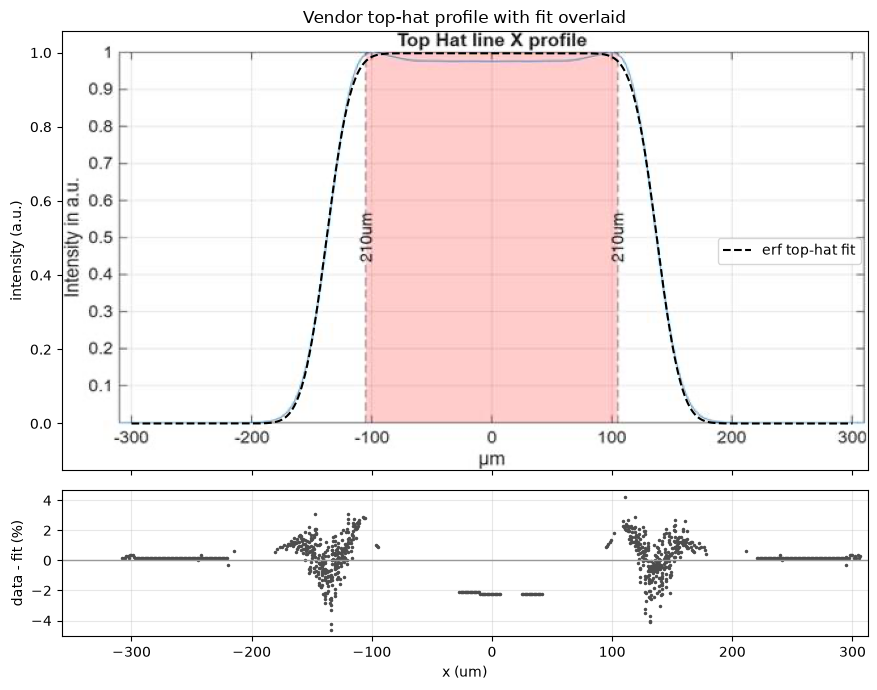

In [14]:
from scipy.optimize import curve_fit

def tophat_fit_model(x, A, a, sigma, x0):
    '''Amplitude A, 50% half-width a, edge width sigma, center offset x0 (all lengths in um).'''
    return A * tophat_1d(x - x0, a, sigma)

popt, pcov = curve_fit(tophat_fit_model, x_data, I_data, p0=[1, 140, 20, 0])
perr = np.sqrt(np.diag(pcov))
A_fit, a_fit, sigma_fit, x0_fit = popt
resid = I_data - tophat_fit_model(x_data, *popt)
print(f"a = {a_fit:.1f} +/- {perr[1]:.1f} um   (50% half-width)")
print(f"sigma = {sigma_fit:.2f} +/- {perr[2]:.2f} um   (10-90% edge = {2.563*sigma_fit:.1f} um)")
print(f"50% point sits {(a_fit - 105)/sigma_fit:.2f} sigma outside the 105 um flat edge")
print(f"rms residual = {np.sqrt(np.mean(resid**2)):.3f}")

# overlay the fit on the vendor plot, with residuals underneath
H, W = vendor_img.shape[:2]
extent = [x_of_col(-0.5), x_of_col(W - 0.5), I_of_row(H - 0.5), I_of_row(-0.5)]
fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1]})
ax.imshow(vendor_img, extent=extent, aspect="auto")
x_plot = np.linspace(-300, 300, 1201)
ax.plot(x_plot, tophat_fit_model(x_plot, *popt), "k--", lw=1.5, label="erf top-hat fit")
ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
ax.set_ylabel("intensity (a.u.)")
ax.set_title("Vendor top-hat profile with fit overlaid")
ax.legend(loc="center right")

ax_res.plot(x_data, 100*resid, ".", color="0.3", ms=3)
ax_res.axhline(0, color="0.6", lw=1)
ax_res.set_xlabel("x (um)"); ax_res.set_ylabel("data - fit (%)")
ax_res.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Fit result: $a = 137.4$ μm, $\sigma = 16.1$ μm (10–90% edge = 41 μm). The 50% point sits $2.0\,\sigma$ outside the edge of the 210 μm flat region. Residuals stay within ±4% on the edges (about one pixel of the image) and are −2% at the center, from the small dip in the vendor profile that the model leaves out.

BTW residuals are poportional to the peak intensity. ALSO the noise around the steep peaks is a function of resolution claude things (hard for angles). Residual RMS is 1.3%. NOTE: ALSO WE SHOULD SWEEP A UNIFORM BACKGROUND OF 10^-8 to 10_3 TO SEE WHAT HURST. THIS IS NOT A "DESIGNED FALL OFF" THIS IS BACKGROUND LEAKAGE DUE TO IMPERFECTIONS OF ALL SORTS.

Caveat: the plot only resolves intensity down to about 1%. Below that, the erf tail is an extrapolation, and real optics usually have a scattered-light floor well above it, so model that floor separately (`eps_bg`).

### Top-hat on our grid

The fixed optic makes a flat region of 40 μm (x) × 160 μm (y), centered on the imaging array; x is the side facing the clock array. The edge blur is scaled from the vendor fit above ($\sigma = 16.1$ μm for a 210 μm flat region), keeping the 50% point $2.0\,\sigma$ outside the flat region. We don't yet know how the edge scales, so there are two cases:

- `long_side`: both edges scale with the 160 μm side (one blur for the whole pattern, as if the vendor example were simply shrunk)
- `own_side`: each edge scales with its own side, so the 40 μm side gets a 4× sharper edge

`eps_bg` is a uniform background floor (fraction of peak) for light leaking from imperfections; 0 means the ideal designed shape only.

After the top-hat cell, `beam_model` picks which model, Gaussian or top-hat, feeds `blue_intensity` for the rest of the notebook.

In [15]:
W_x, W_y = 40e-6, 160e-6                 # flat region of the mask, m; x faces the clock array
edge_case = "long_side"                  # "long_side" or "own_side"
eps_bg = 0                               # background floor as a fraction of peak; sweep 1e-8 to 1e-3 later

def tophat_edges(edge_case):
    '''50% half-widths and edge blurs (a_x, sigma_x, a_y, sigma_y), in m, scaled from the vendor fit.'''
    sigma_per_width = sigma_fit / 210        # vendor fit: sigma = 16.1 um for a 210 um flat region
    edge_offset = (a_fit - 105) / sigma_fit  # vendor fit: 50% point sits ~2.0 sigma outside the flat region
    if edge_case == "long_side":             # one blur for the whole pattern, set by the long side
        sigma_x = sigma_y = sigma_per_width * max(W_x, W_y)
    elif edge_case == "own_side":            # each edge scales with its own side
        sigma_x, sigma_y = sigma_per_width * W_x, sigma_per_width * W_y
    else:
        raise ValueError(f"unknown edge_case {edge_case!r}")
    return W_x/2 + edge_offset*sigma_x, sigma_x, W_y/2 + edge_offset*sigma_y, sigma_y

def tophat_intensity(X, Y, edge_case, eps_bg=0.0):
    '''Top-hat intensity (W/m^2) at positions X, Y (m), plus a uniform background floor eps_bg (fraction of peak).'''
    a_x, sigma_x, a_y, sigma_y = tophat_edges(edge_case)
    return peak_intensity * (tophat_1d(X, a_x, sigma_x) * tophat_1d(Y, a_y, sigma_y) + eps_bg)

blue_intensity_tophat = tophat_intensity(X, Y, edge_case, eps_bg)  # W/m^2

a_x, sigma_x, a_y, sigma_y = tophat_edges(edge_case)
frac = blue_intensity_tophat / peak_intensity
print(f"edge case '{edge_case}': sigma_x = {sigma_x*1e6:.2f} um (10-90% edge {2.563*sigma_x*1e6:.1f} um), 50% point at x = {a_x*1e6:.1f} um")
print(f"imaging-array corner (18, 38) um sees {tophat_intensity(18e-6, 38e-6, edge_case)/peak_intensity:.3f} of peak")
print(f"clock array sees {frac.min():.1e} to {frac.max():.1e} of peak (max s = {s*frac.max():.2g})")

edge case 'long_side': sigma_x = 12.25 um (10-90% edge 31.4 um), 50% point at x = 44.7 um
imaging-array corner (18, 38) um sees 0.985 of peak
clock array sees 9.8e-07 to 3.4e-02 of peak (max s = 1.4)


In [16]:
beam_model = "tophat"                    # "gaussian" or "tophat"
blue_intensity = {"gaussian": blue_intensity_gauss, "tophat": blue_intensity_tophat}[beam_model]   # W/m^2, used below

Resonant 1S0 light shift from the 1P1 line (two-level atom, valid only for $s \ll 1$):
$$\delta\nu_{1P1} = \frac{\Gamma}{2\pi}\,\frac{s}{4}\,\frac{x}{1+x^2}, \qquad x = \frac{2\Delta}{\Gamma}, \qquad s = \frac{I}{I_{sat}}$$

- $\Delta = \omega_{laser} - \omega_{atom}$ (rad/s), $\Gamma = 2\pi \times 29.1$ MHz
- Zero on resonance, largest at $\Delta = \pm\Gamma/2$; red detuning ($\Delta < 0$) lowers 1S0
- Far from resonance ($|\Delta| \gg \Gamma$) it becomes $\frac{1}{2\pi}\frac{s\,\Gamma^2}{8\Delta}$, the same $1/\Delta$ behavior as the $V_{ac}$ formula above

In [17]:
def shift_1P1(s, Delta):
    '''1S0 light shift from the resonant 1P1 line, in Hz.
    s = I/I_sat at the atom; Delta = laser minus atom resonance, rad/s. Only valid for s << 1.'''
    x = 2*Delta/Gamma_1p1
    return (Gamma_1p1/(2*pi)) * s * x / (4*(1 + x**2))

Photon scattering rate from 1S0 (two-level atom, including saturation, valid for any $s$):
$$R_{sc} = \frac{\Gamma}{2}\,\frac{s}{1 + s + x^2}, \qquad x = \frac{2\Delta}{\Gamma}$$

- Units: photons per second
- Largest on resonance; saturates at $\Gamma/2$ for $s \gg 1$
- For $s \ll 1$ it becomes $\frac{\Gamma}{2}\frac{s}{1+x^2}$, and $2\pi\,\delta\nu_{1P1}/R_{sc} = \Delta/\Gamma$: within a linewidth of resonance, scattering is as big as the shift

In [18]:
def scatter_rate_1P1(s, Delta):
    '''Photons scattered per second by an atom in 1S0. Includes saturation, valid for any s.'''
    x = 2*Delta/Gamma_1p1
    return (Gamma_1p1/2) * s / (1 + s + x**2)

In [19]:
Delta = 0 # on resonance: worst case for scattering (not focusing on the light shift for now); was -Gamma_1p1/2
s_atoms = blue_intensity/I_sat
print("Maximum s experienced by clock atoms: " + str(np.max(s_atoms)))
rate_grid = scatter_rate_1P1(s_atoms, Delta)    # photons/s at each clock site
shift_1S0 = Vac_1S0_nonres * blue_intensity/h + shift_1P1(s_atoms, Delta) # total shift of 1S0 including resonant 1P1 contribution
shift_3P0 = Vac_3P0 * blue_intensity/h
shift_clock = shift_3P0 - shift_1S0
# print(f"Shift_3P0 = {shift_3P0:.3e} Hz")
# print("Shift_3P0 Grid (Hz):");print(shift_3P0)
# print("Shift_1S0 Grid (Hz):");print(shift_1S0)
# print("Shift_Clock Grid (Hz):");print(shift_clock)
print("Scattering Rate Grid (photons/s):");print(rate_grid)

Maximum s experienced by clock atoms: 1.3770675373843582
Scattering Rate Grid (photons/s):
[[5.30101878e+07 3.56253657e+07 1.93587236e+07 8.50667314e+06
  3.13539638e+06 1.00626623e+06 2.87480087e+05 7.38119079e+04
  1.70868455e+04 3.56878199e+03]
 [5.30101883e+07 3.56253661e+07 1.93587240e+07 8.50667331e+06
  3.13539645e+06 1.00626625e+06 2.87480093e+05 7.38119095e+04
  1.70868459e+04 3.56878207e+03]
 [5.30101884e+07 3.56253662e+07 1.93587240e+07 8.50667333e+06
  3.13539646e+06 1.00626626e+06 2.87480094e+05 7.38119097e+04
  1.70868460e+04 3.56878208e+03]
 [5.30101884e+07 3.56253662e+07 1.93587240e+07 8.50667334e+06
  3.13539646e+06 1.00626626e+06 2.87480094e+05 7.38119097e+04
  1.70868460e+04 3.56878209e+03]
 [5.30101884e+07 3.56253662e+07 1.93587240e+07 8.50667334e+06
  3.13539646e+06 1.00626626e+06 2.87480094e+05 7.38119097e+04
  1.70868460e+04 3.56878209e+03]
 [5.30101884e+07 3.56253662e+07 1.93587240e+07 8.50667334e+06
  3.13539646e+06 1.00626626e+06 2.87480094e+05 7.38119097e+04


## 556 nm imaging: tweezer-induced detuning of the clock atoms

For 556 nm imaging, the imaged atoms sit in 780 nm tweezers while the clock atoms stay in 460.862 nm tweezers. (399 nm imaging keeps both arrays in the 460 nm tweezers, so nothing changes there.) Each tweezer shifts 1S0 and 3P1 by different amounts, which moves the 556 nm resonance by
$$\delta\nu_{556} = -\left(\frac{\alpha_{3P1}}{\alpha_{1S0}} - 1\right)\frac{U}{h},$$
where $U$ is the 1S0 trap depth. The imaging light is tuned $+\Gamma$ from the imaged atoms' own (780 nm-trapped) resonance, so the clock atoms see
$$\Delta_{clock} = \Gamma + \delta\nu_{556}(780\ \mathrm{nm},\, U_{img}) - \delta\nu_{556}(460.862\ \mathrm{nm},\, U_{clock}).$$
Because $\Gamma/2\pi$ is only 183 kHz, MHz-scale trap shifts put the clock atoms many linewidths off resonance, which cuts their scattering by the factor $1 + (2\Delta/\Gamma)^2$ in `scatter_rate`.

Polarizabilities: a sum over states with the reduced E1 matrix elements and NIST energies tabulated by Tang, Yu, Jiang & Dong, [arXiv:1712.08888](https://arxiv.org/abs/1712.08888) (Tables 2–4; experimental values for the strongest 1S0 lines, as in their Table 4), plus their core and "all other states" contributions. 3P1 (J = 1) has a tensor part, so the shift depends on the sublevel. For ¹⁷¹Yb we use F′ = 3/2 with |mF′| = 1/2 or 3/2, and linear tweezer polarization at angle θ = 0 or 90° to the quantization axis. The shift is linear in cos²θ, so every other angle lies between these, and the worst case over all of them is used below. The checks reproduce the paper's static polarizabilities and its 1S0–3P1 magic wavelengths, including the measured 1035.68 nm π magic wavelength (Zheng et al., [arXiv:2011.06759](https://arxiv.org/abs/2011.06759)).

Inputs: clock array in 460.862 nm tweezers, 230 μK deep; imaging array in 780.0 nm tweezers, 10 MHz deep (wavelengths taken as vacuum). Not included: Zeeman shifts from the bias field.

In [ ]:
from sympy import Rational, S
from scipy.optimize import brentq

cm1_to_au = 4.556335252912e-6          # 1 cm^-1 in Hartree
# Tang, Yu, Jiang & Dong, arXiv:1712.08888, Tables 2-4: NIST energies (cm^-1), reduced E1 matrix elements (a.u.)
pol_from_1S0 = [  # (upper state, energy, J, RME); experimental RMEs for the strongest lines, as in their Table 4
    ("6s6p 1P1", 25068.222, 1, 4.148), ("6s6p 3P1", 17992.007, 1, 0.543), ("6s7p 1P1", 40563.97, 1, 0.67),
    ("6s7p 3P1", 38174.17, 1, 0.08), ("6s8p 1P1", 44017.60, 1, 0.21), ("6s8p 3P1", 43659.38, 1, 0.014),
    ("4f13 5d 6s2 (7/2,5/2)1", 28857.014, 1, 2.04)]
pol_other_1S0, pol_core = 2.04, 7.27    # "all other states" (static) and core contributions, a.u.
E_3P1 = 17992.007
pol_from_3P1 = [  # (other state, energy, J, RME), CI+MBPT values
    ("6s2 1S0", 0.0, 0, 0.58), ("5d6s 3D1", 24489.102, 1, 2.57), ("5d6s 3D2", 24751.948, 2, 4.45),
    ("5d6s 1D2", 27677.665, 2, 0.46), ("6s6d 3D1", 39808.72, 1, 1.57), ("6s6d 3D2", 39838.04, 2, 2.72),
    ("6s6d 1D2", 40061.51, 2, 0.53), ("6s7d 3D1", 44311.38, 1, 2.47), ("6s7d 3D2", 44313.05, 2, 1.67),
    ("6s7d 1D2", 44357.60, 2, 0.86), ("6s7s 3S1", 32694.692, 1, 3.47), ("6s7s 1S0", 34350.65, 0, 0.24),
    ("6s8s 3S1", 41615.04, 1, 1.00), ("6s8s 1S0", 41939.90, 0, 0.29), ("6p2 3P0", 42436.91, 0, 2.59),
    ("6p2 3P1", 43805.42, 1, 0.18), ("6p2 3P2", 44760.37, 2, 2.92)]
pol_other_3P1 = 16.87

_E1 = np.array([E for _, E, _, _ in pol_from_1S0])*cm1_to_au
_d1 = np.array([d for _, _, _, d in pol_from_1S0])
_dE3 = (np.array([E for _, E, _, _ in pol_from_3P1]) - E_3P1)*cm1_to_au
_d3 = np.array([d for _, _, _, d in pol_from_3P1])
_J3 = np.array([Ji for _, _, Ji, _ in pol_from_3P1])
_tensor_w = (4*np.sqrt(5/(6*2*3*5)) * (-1.0)**(1 + _J3)                       # J = 1 prefactor and phase
             * np.array([float(wigner_6j(1, 1, int(Ji), 1, 1, 2)) for Ji in _J3]))

def pol_1S0(lam_nm):
    '''Dynamic polarizability of 1S0 (a.u.) at vacuum wavelength lam_nm (np.inf = static).'''
    w = (1e7/np.asarray(lam_nm, float)*cm1_to_au)[..., None]
    return (2/3*_d1**2*_E1/(_E1**2 - w**2)).sum(-1) + pol_other_1S0 + pol_core

def pol_3P1(lam_nm):
    '''Scalar and tensor dynamic polarizabilities of 3P1 (J = 1), a.u.'''
    w = (1e7/np.asarray(lam_nm, float)*cm1_to_au)[..., None]
    term = _d3**2*_dE3/(_dE3**2 - w**2)
    return (2/9*term).sum(-1) + pol_other_3P1 + pol_core, (_tensor_w*term).sum(-1)

# 171Yb 3P1 F'=3/2 (I = 1/2): tensor part in the F basis (trap shifts << the ~6 GHz hyperfine splitting)
_J, _I, _F = 1, Rational(1, 2), Rational(3, 2)
tensor_F_factor = float((-1)**(_I + _J + _F) * S((_F*(2*_F-1)*(2*_F+1)*(2*_J+3)*(2*_J+1)*(_J+1))
                        / ((2*_F+3)*(_F+1)*_J*(2*_J-1)))**Rational(1, 2) * wigner_6j(_F, _J, _I, _J, _F, 2))

def pol_3P1_sublevel(lam_nm, mF, theta_deg):
    '''171Yb 3P1 F'=3/2, |mF'| polarizability (a.u.) for linear tweezer polarization at theta to the quantization axis.'''
    aS, aT = pol_3P1(lam_nm)
    F = 1.5
    return aS + tensor_F_factor*aT*(3*np.cos(np.radians(theta_deg))**2 - 1)/2 * (3*mF**2 - F*(F+1))/(F*(2*F-1))

def line556_shift_per_depth(lam_nm, mF, theta_deg):
    '''Shift of the 556 nm line per unit 1S0 trap depth: delta_nu / (U/h) = -(alpha_3P1 / alpha_1S0 - 1).'''
    return -(pol_3P1_sublevel(lam_nm, mF, theta_deg)/pol_1S0(lam_nm) - 1)

# checks against the paper: static values (its Table 4) and its 1S0-3P1 magic wavelengths
aS0, aT0 = pol_3P1(np.inf)
print(f"static: alpha(1S0) = {pol_1S0(np.inf):.1f} a.u. (paper 135), alpha_S(3P1) = {aS0:.1f} (paper 328), "
      f"alpha_T(3P1) = {aT0:.1f} (paper 24.1)")
lam_scan = np.linspace(560, 1600, 20801)
aS_scan, aT_scan = pol_3P1(lam_scan)
for MJ, paper in [(0, "612.9, 1035.7 (measured: 1035.68)"), (1, "858(12), 1036.0, 1517.68")]:
    diff = pol_1S0(lam_scan) - (aS_scan + (3*MJ**2 - 2)*aT_scan)        # J basis, polarization along the axis
    flips = np.flatnonzero((np.sign(diff[:-1]) != np.sign(diff[1:])) & (np.abs(diff[:-1]) < 50) & (np.abs(diff[1:]) < 50))
    f = lambda l: float(pol_1S0(l) - (pol_3P1(l)[0] + (3*MJ**2 - 2)*pol_3P1(l)[1]))
    found = ", ".join(f"{brentq(f, lam_scan[i], lam_scan[i+1]):.1f}" for i in flips)
    print(f"magic wavelengths, |MJ| = {MJ}: {found} nm (paper: {paper} nm)")

In [ ]:
lam_tweezer_clock, U_clock_uK = 460.862, 230       # clock array: wavelength (nm, vacuum) and 1S0 trap depth (uK)
lam_tweezer_img, U_img_MHz = 780.0, 10.0           # imaging array for 556 nm imaging: wavelength (nm) and trap depth U/h (MHz)
U_clock_MHz = U_clock_uK * sp.constants.k * 1e-6 / h / 1e6
Gamma_556_MHz = transition_from_1S0["6s6p 3P1"].Gamma/(2*pi)/1e6
Delta_img_556_MHz = Gamma_556_MHz                  # imaging light: +Gamma from the imaged atoms' own resonance

print(f"1S0 polarizability: {pol_1S0(lam_tweezer_clock):.1f} a.u. at {lam_tweezer_clock} nm, "
      f"{pol_1S0(lam_tweezer_img):.1f} a.u. at {lam_tweezer_img} nm")
print(f"trap depths: clock array {U_clock_uK} uK = {U_clock_MHz:.2f} MHz, imaging array {U_img_MHz} MHz")
D_clock = []
for mF in (0.5, 1.5):
    for th_img in (0, 90):
        for th_clk in (0, 90):
            d_img = line556_shift_per_depth(lam_tweezer_img, mF, th_img) * U_img_MHz
            d_clk = line556_shift_per_depth(lam_tweezer_clock, mF, th_clk) * U_clock_MHz
            D_clock.append(Delta_img_556_MHz + d_img - d_clk)
            print(f"  |mF'| = {mF}, theta(780) = {th_img:>2}, theta(460) = {th_clk:>2}: 556 shift {d_img:+6.2f} MHz (imaged), "
                  f"{d_clk:+6.2f} MHz (clock) -> Delta_clock = {D_clock[-1]:+6.2f} MHz = {D_clock[-1]/Gamma_556_MHz:+4.0f} Gamma")
D_clock = np.array(D_clock)
if D_clock.min() < 0 < D_clock.max():      # the range crosses zero: some sublevel/polarization is exactly resonant
    Delta_clock_556 = 0.0
    print("WARNING: the range crosses zero, so some polarization angle is resonant; using Delta_clock = 0 (worst case)")
else:                                       # the shift is linear in cos^2(theta), so the extremes bound every angle
    Delta_clock_556 = 2*pi*1e6 * D_clock[np.argmin(np.abs(D_clock))]
x_wc = 2*Delta_clock_556/(2*pi*1e6)/Gamma_556_MHz
print(f"Delta_clock range {D_clock.min():+.2f} to {D_clock.max():+.2f} MHz; worst case (used below) "
      f"{Delta_clock_556/(2*pi)/1e6:+.2f} MHz = {Delta_clock_556/(2*pi)/1e6/Gamma_556_MHz:+.0f} Gamma, "
      f"so the clock atoms scatter {(1 + x_wc**2)/5:.0f}x less than at Delta = +Gamma")

In [ ]:
# 556 nm line shift per unit trap depth vs tweezer wavelength, around 460 nm and 780 nm, for each sublevel/polarization
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
lam_460 = np.linspace(455, 468, 1301); lam_780 = np.linspace(760, 800, 801)
styles = {(0.5, 0): ("tab:green", "-"), (0.5, 90): ("tab:green", "--"), (1.5, 0): ("tab:purple", "-"), (1.5, 90): ("tab:purple", "--")}
for (mF, th), (col, ls) in styles.items():
    for ax, lam in [(ax0, lam_460), (ax1, lam_780)]:
        ax.plot(lam, line556_shift_per_depth(lam, mF, th), color=col, ls=ls, lw=1.8,
                label=f"|mF'| = {mF:g}, θ = {th}°" if ax is ax0 else None)
for E_up in (39808.72, 39838.04):                      # 3P1 -> 6s6d 3D1, 3D2 resonances
    ax0.axvline(1e7/(E_up - E_3P1), color="0.6", ls=":", lw=1)
ax0.text(1e7/(39808.72 - E_3P1), 4.5, " 3P1→6s6d ³D", fontsize=8, color="0.4", va="top")
for ax, lam_tw, name in [(ax0, lam_tweezer_clock, "clock tweezer"), (ax1, lam_tweezer_img, "imaging tweezer (556 imaging)")]:
    ax.axvline(lam_tw, color="k", lw=1.2)
    ax.text(lam_tw, ax.get_ylim()[1] if ax is ax1 else 4.5, f" {name}\n {lam_tw} nm", fontsize=8, va="top")
    ax.axhline(0, color="0.7", lw=0.8)
    ax.set_xlabel("tweezer wavelength (nm, vacuum)")
ax0.set_ylim(-15, 5)
ax0.set_ylabel("556 nm line shift per unit trap depth, δν / (U/h)")
ax0.set_title("Around the clock tweezer", fontsize=10); ax1.set_title("Around the 556 imaging tweezer", fontsize=10)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("How each tweezer moves the 556 nm resonance (¹⁷¹Yb, 3P1 F′ = 3/2; θ = tweezer polarization angle to the field)", fontsize=11)
plt.show()

## Two imaging lines: 399 nm and 556 nm

Everything below runs for both imaging lines. Each line is a dict holding what depends on it: the resonant transition, its linewidth and saturation intensity, the imaging intensity `s` and pulse length `tau`, the detuning `Delta`, and the non-resonant shifts of 1S0 and 3P0 at that wavelength.

| | 399 nm (1S0–1P1) | 556 nm (1S0–3P1) |
|---|---|---|
| $\Gamma/2\pi$ | 29.1 MHz | 183 kHz |
| pulse `tau` | 6.3 μs (Falconi) | 4 ms |
| tweezers | both arrays in 460.862 nm | imaging array in 780 nm, clock array in 460.862 nm |
| detuning `Delta` seen by the clock atoms | 0 (worst case for scattering) | from the tweezer shifts above (worst case, about $+49\,\Gamma$ with the current inputs) |
| imaging `s` | 40 | 40 (assumed the same; change it in `lines`) |

For each line, the non-resonant 1S0 shift sums every other 1S0 transition (at 556 nm that now includes 1P1). The resonant formulas are the same two-level expressions as above, with that line's $\Gamma$. The beam shape (top-hat or Gaussian) is the same for both lines.

In [ ]:
t3P1 = transition_from_1S0["6s6p 3P1"]               # 556 nm intercombination line, Gamma/2pi = 183 kHz
all_from_1S0 = {**transition_from_1S0, "6s6p 1P1": t1P1}

def make_line(name, t, s_img, tau, Delta_img, Delta_clock, cmap):
    '''Collect everything that depends on the imaging line. t = the resonant transition from 1S0;
    Delta_img / Delta_clock = detuning of the imaging light from the imaged / clock atoms' resonance (rad/s);
    cmap = colormap for this line's scattering plots. "Delta" in the dict is the clock atoms' detuning.'''
    nonres_1S0 = {k: v for k, v in all_from_1S0.items() if v is not t}   # all other 1S0 lines are non-resonant
    I_sat_line = hbar * t.Gamma * t.omega**3 / (12*pi*c**2)               # W/m^2
    return dict(name=name, t=t, Gamma=t.Gamma, s=s_img, tau=tau, Delta=Delta_clock, Delta_img=Delta_img, cmap=cmap,
                I_sat=I_sat_line, I0=s_img*I_sat_line,                     # I0 = peak intensity on the imaging array
                Vac_1S0_nonres=Vac(nonres_1S0, ground)(t.omega) + Vac_offset_1S0,
                Vac_3P0=Vac(transition_from_3P0, metastable)(t.omega))

def shift_resonant(s_local, Delta, Gamma):
    '''1S0 light shift (Hz) from the resonant imaging line: same two-level formula as shift_1P1, valid for s << 1.'''
    x = 2*Delta/Gamma
    return (Gamma/(2*pi)) * s_local * x / (4*(1 + x**2))

def scatter_rate(s_local, Delta, Gamma):
    '''Photons/s scattered from 1S0 on the imaging line: same two-level formula as scatter_rate_1P1.'''
    x = 2*Delta/Gamma
    return (Gamma/2) * s_local / (1 + s_local + x**2)

def tophat_fraction(X, Y, edge_case, eps_bg=0.0):
    '''Top-hat intensity as a fraction of the peak (same shape for both lines), plus the background floor.'''
    return tophat_intensity(X, Y, edge_case, eps_bg) / peak_intensity

lines = {
    "399": make_line("399 nm (1S0-1P1)", t1P1, s_img=s, tau=6.3e-6, Delta_img=Delta, Delta_clock=Delta, cmap="Blues"),   # Falconi fast imaging; Delta from above
    "556": make_line("556 nm (1S0-3P1)", t3P1, s_img=40, tau=4e-3, Delta_img=t3P1.Gamma, Delta_clock=Delta_clock_556,
                     cmap="Greens"),   # s assumed same as 399; +Gamma from the imaged atoms, Delta_clock from the tweezer shifts
}
for L in lines.values():
    print(f"{L['name']}: Gamma/2pi = {L['Gamma']/(2*pi)/1e3:.0f} kHz, I_sat = {L['I_sat']/10:.3g} mW/cm^2, "
          f"I0 = {L['I0']/10:.3g} mW/cm^2, tau = {L['tau']*1e6:g} us, Delta = {L['Delta_img']/L['Gamma']:+.1f} Gamma from the imaged atoms, "
          f"{L['Delta']/L['Gamma']:+.1f} Gamma from the clock atoms")
    print(f"    each imaged atom scatters {scatter_rate(L['s'], L['Delta_img'], L['Gamma'])*L['tau']:.0f} photons per image")
    print(f"    non-resonant shifts per unit s: 1S0 {L['Vac_1S0_nonres']*L['I_sat']/h:+.3g} Hz, 3P0 {L['Vac_3P0']*L['I_sat']/h:+.3g} Hz")

## Maps of the clock array

Scattering rate and clock shift at each clock site, for both top-hat edge cases, using each line's `Delta` and the current `eps_bg`. There is one figure per imaging line. The color scales are logarithmic and set separately for each panel, so compare panels by their colorbar values (and the max in each title), not by color.

- Clock shift = shift(3P0) − shift(1S0), where the 1S0 part includes the resonant imaging-line piece.
- × marks sites with s > 0.1, where the light-shift formula (valid only for $s \ll 1$) breaks down. The scattering rate is valid at any s.
- With `eps_bg = 0` these maps show the designed shape only; real leakage will set a floor.

In [21]:
from matplotlib.colors import LogNorm

def clock_effects(frac, line):
    '''Scattering rate (photons/s), clock shift (Hz), and s at the clock atoms, for intensity fraction frac
    (of the imaging peak) on a given imaging line. Clock shift = shift(3P0) - shift(1S0).'''
    I = frac * line["I0"]
    s_I = I / line["I_sat"]
    rate = scatter_rate(s_I, line["Delta"], line["Gamma"])
    shift = (line["Vac_3P0"] - line["Vac_1S0_nonres"]) * I / h - shift_resonant(s_I, line["Delta"], line["Gamma"])
    return rate, shift, s_I

def log_norm(vmin, vmax):
    '''Log color scale that still works when every value is the same (e.g. a uniform background).'''
    return LogNorm(vmin, vmax if vmax > vmin else 1.01*vmin)

In [ ]:
cases = {"own_side": "own_side (each edge scales with its own side)",
         "long_side": "long_side (same edge on both axes)"}

def plot_maps(line):
    '''2x2 maps of the clock array for one imaging line: rows = scattering rate, |clock shift|; columns = edge case.'''
    quantities = [("rate", line["cmap"], "scattering rate (photons/s)"),
                  ("shift", "Purples", "|clock shift| (Hz)")]
    fig, axes = plt.subplots(2, 2, figsize=(8.5, 12.5), sharex=True, sharey=True, layout="constrained")
    invalid_handle = None
    for col, (case, case_label) in enumerate(cases.items()):
        rate, shift, s_sites = clock_effects(tophat_fraction(X, Y, case, eps_bg), line)
        values = {"rate": rate, "shift": np.abs(shift)}
        for row, (key, cmap, label) in enumerate(quantities):
            ax = axes[row, col]
            vals = values[key]
            sc = ax.scatter(X*1e6, Y*1e6, c=vals, cmap=cmap, norm=log_norm(vals.min(), vals.max()),
                            s=110, edgecolors="0.5", linewidths=0.5)
            fig.colorbar(sc, ax=ax, label=label, shrink=0.9)
            title = f"{case_label}\n{label.split(' (')[0]}, max {vals.max():.1e}"
            if key == "shift":
                sign = "+" if np.all(shift > 0) else "−" if np.all(shift < 0) else "±"
                title += f" (sign {sign})"
                invalid = s_sites > 0.1          # shift formula assumes s << 1
                if invalid.any():
                    invalid_handle = ax.scatter(X[invalid]*1e6, Y[invalid]*1e6, marker="x", c="k", s=40, lw=1,
                                                label="s > 0.1: shift formula not valid (atom saturated)")
            ax.set_title(title, fontsize=10)
            ax.set_aspect("equal")
    for ax in axes[-1]: ax.set_xlabel("x from imaging-array center (um)")
    for ax in axes[:, 0]: ax.set_ylabel("y (um)")
    if invalid_handle is not None:
        fig.legend(handles=[invalid_handle], loc="outside lower center")
    fig.suptitle(f"{line['name']}: clock array during imaging\n"
                 f"s = {line['s']} on the imaging array, Δ_clock = {line['Delta']/line['Gamma']:+.2f} Γ, eps_bg = {eps_bg:g}")
    plt.show()

for line in lines.values():
    plot_maps(line)

## Uniform background floor (`own_side`)

For `own_side` the designed edge reaches the clock array at less than $10^{-40}$ of peak, so any realistic leakage floor `eps_bg` sets everything there. There is one figure per imaging line. Each column uses a different `eps_bg`; each row shares one color scale, so the panels compare directly. Because the floor is uniform, every site in a panel sees the same value (the printed tables list them, including the site-to-site spread). While $s \ll 1$ at the clock atoms, the scattering rate and clock shift both scale linearly with `eps_bg`.

In [ ]:
eps_bg_values = [1e-6, 1e-5, 1e-4, 1e-3]    # background floor, fraction of peak intensity
case = "own_side"

def plot_eps_sweep(line):
    '''Table and 2 x len(eps_bg_values) maps (scattering rate, |clock shift|) for one imaging line.'''
    results = {e: clock_effects(tophat_fraction(X, Y, case, e), line) for e in eps_bg_values}

    # summary table: with own_side the designed edge is < 1e-40 at the clock array, so the floor sets everything
    print(f"{line['name']}, {case}, Δ_clock = {line['Delta']/line['Gamma']:+.2f} Γ, s = {line['s']} on the imaging array")
    print(f"{'eps_bg':>8} {'s at clock':>11} {'rate (1/s)':>11} {'per us':>8} {'clock shift (Hz)':>17} {'site-to-site spread':>20}")
    for e, (rate, shift, s_sites) in results.items():
        print(f"{e:>8.0e} {s_sites.max():>11.1e} {rate.max():>11.2e} {rate.max()*1e-6:>8.2g} {shift.max():>17.3g} {np.ptp(rate)/rate.max():>20.1e}")

    fig, axes = plt.subplots(2, len(eps_bg_values), figsize=(13, 9.5), sharex=True, sharey=True, layout="constrained")
    invalid_handle = None
    for row, (idx, cmap, label) in enumerate([(0, line["cmap"], "scattering rate (photons/s)"),
                                              (1, "Purples", "|clock shift| (Hz)")]):
        row_vals = [np.abs(results[e][idx]) for e in eps_bg_values]
        # one color scale shared across the row; start it a bit below the minimum so the lowest panel isn't white
        norm = log_norm(0.2*min(v.min() for v in row_vals), max(v.max() for v in row_vals))
        for col, (e, vals) in enumerate(zip(eps_bg_values, row_vals)):
            ax = axes[row, col]
            sc = ax.scatter(X*1e6, Y*1e6, c=vals, cmap=cmap, norm=norm, s=60, edgecolors="0.5", linewidths=0.5)
            ax.set_title(f"eps_bg = {e:.0e}\n{label.split(' (')[0]} = {vals.max():.2g}", fontsize=10)
            ax.set_aspect("equal")
            s_sites = results[e][2]
            if idx == 1 and (s_sites > 0.1).any():      # shift formula assumes s << 1
                invalid_handle = ax.scatter(X[s_sites > 0.1]*1e6, Y[s_sites > 0.1]*1e6, marker="x", c="k", s=30, lw=1,
                                            label="s > 0.1: shift formula not valid (atom saturated)")
        fig.colorbar(sc, ax=axes[row, :], label=label, shrink=0.9)
    for ax in axes[-1]: ax.set_xlabel("x from imaging-array center (um)")
    for ax in axes[:, 0]: ax.set_ylabel("y (um)")
    if invalid_handle is not None:
        fig.legend(handles=[invalid_handle], loc="outside lower center")
    fig.suptitle(f"{line['name']}: clock array with a uniform background floor, {case}, s = {line['s']} on the imaging array, "
                 f"Δ_clock = {line['Delta']/line['Gamma']:+.2f} Γ")
    plt.show()

for line in lines.values():
    plot_eps_sweep(line)

Falconi paper has 6.3us as the blue imaging time which I use.

The goal is to then have scattering rate for nearest atom, times 200, times 6.3us be something like 10^-3 or lower.

I can search over either parameters. (and over gaussian vs flat top zone to get this).

## Search over edge width and background floor

Requirement, worst case (every clock atom sees the nearest atom's light):
$$N_{atoms}\; R_{sc}(\text{nearest})\; \tau_{img} < p_{max}$$
with $N_{atoms} = 200$ and $p_{max} = 10^{-3}$ shared, and each line's own pulse length and detuning (399 nm: $\tau_{img} = 6.3$ μs, $\Delta = 0$; 556 nm: $\tau_{img} = 4$ ms, $\Delta = \Delta_{clock}$ from the tweezer shifts, worst case).

Since $s \ll 1$ at the clock atoms, $R_{sc}$ is linear in intensity, so the requirement becomes one intensity budget at the nearest atom:
$$f_{edge}(d) + \epsilon_{bg} < \epsilon_{max} = \frac{p_{max}\,(1 + x^2)}{(\Gamma/2)\, s\, N_{atoms}\, \tau_{img}}, \qquad x = \frac{2\Delta}{\Gamma}$$
using that line's $\Gamma$. Here $d$ is the distance from the flat region's edge (20 μm) to the nearest clock column (67 μm), and $f_{edge}$ comes from one of two edge models (the same optics for both lines):

- Model A: the erf top-hat (vendor shape), parameterized by its 10–90% edge width
- Model B: flat to the array edge $x_0$, then $\exp(-2(|x|-x_0)^2/w_{edge}^2)$, parameterized by $w_{edge}$ (its 10–90% width is $0.843\,w_{edge}$)

In [ ]:
# requirement (worst case): every clock atom sees the nearest atom's light
N_atoms = 200                 # clock-array sites
p_max = 1e-3                  # allowed expected scattered photons, summed over the clock array, per image
                              # pulse length tau and detuning Delta come from each line in `lines`

def photons_per_image(frac, line):
    '''Expected scattered photons summed over the clock array per imaging pulse,
    if all N_atoms atoms see intensity fraction frac (of peak), like the nearest one.'''
    return N_atoms * scatter_rate(line["s"]*frac, line["Delta"], line["Gamma"]) * line["tau"]

def intensity_budget(line):
    '''Largest intensity fraction at the nearest atom that keeps photons_per_image below p_max (s << 1 there).'''
    x_det = 2*line["Delta"]/line["Gamma"]
    return p_max * (1 + x_det**2) / ((line["Gamma"]/2) * line["s"] * N_atoms * line["tau"])

for L in lines.values():
    e_max = intensity_budget(L)
    print(f"{L['name']}: {N_atoms} atoms x {L['tau']*1e6:g} us, Δ_clock = {L['Delta']/L['Gamma']:+.1f} Γ, s = {L['s']}, p_max = {p_max:g}")
    print(f"    intensity budget at the nearest atom: eps_max = {e_max:.2e} of peak "
          f"(check: {photons_per_image(e_max, L):.4e} photons per image)")

In [25]:
x_flat_edge = W_x/2                        # edge of the flat region, m (20 um)
x_nearest = X.min()                        # nearest clock column, m (67 um); those sites sit near y = 0,
                                           # deep inside the 160 um flat region in y, so the y-factor is ~1
edge_offset = (a_fit - 105) / sigma_fit    # vendor fit: 50% point sits ~2.0 sigma outside the flat region

def edge_A(x, edge_10_90):
    '''Model A (erf top-hat, vendor shape): intensity fraction at x for a 10-90% edge width edge_10_90 (m).'''
    sigma_e = edge_10_90 / 2.563
    return tophat_1d(x, x_flat_edge + edge_offset*sigma_e, sigma_e)

def edge_B(x, w_edge, x0=x_flat_edge):
    '''Model B: flat out to x0, then a Gaussian falloff exp(-2 (|x| - x0)^2 / w_edge^2). 10-90% width = 0.843 w_edge.'''
    d = np.clip(np.abs(x) - x0, 0, None)
    return np.exp(-2 * d**2 / w_edge**2)

# consistency check: model A at the two old edge cases vs the full-grid top-hat model
for case in ("own_side", "long_side"):
    edge_10_90 = 2.563 * tophat_edges(case)[1]
    grid_val = tophat_intensity(X, Y, case).max() / peak_intensity
    print(f"{case}: 10-90% edge {edge_10_90*1e6:.1f} um -> model A {edge_A(x_nearest, edge_10_90):.3e}, full grid {grid_val:.3e}")

own_side: 10-90% edge 7.8 um -> model A 7.638e-41, full grid 7.638e-41
long_side: 10-90% edge 31.4 um -> model A 3.443e-02, full grid 3.443e-02


In [26]:
from scipy.optimize import brentq

edge_widths = np.linspace(0.5e-6, 40e-6, 160)    # m; model A: 10-90% edge width, model B: w_edge
eps_grid = np.logspace(-14, -3, 111)              # background floor, fraction of peak
W_grid, E_grid = np.meshgrid(edge_widths, eps_grid)
frac_A = edge_A(x_nearest, W_grid) + E_grid       # intensity fraction at the nearest atom (same optics for both lines)
frac_B = edge_B(x_nearest, W_grid) + E_grid

search = {}
print(f"nearest atom is {(x_nearest - x_flat_edge)*1e6:.0f} um past the flat edge")
for key, L in lines.items():
    e_max = intensity_budget(L)
    # the two ends of the boundary: no background at all, or a perfectly sharp edge
    A_max = brentq(lambda w: edge_A(x_nearest, w) - e_max, 1e-7, 1e-4)
    B_max = brentq(lambda w: edge_B(x_nearest, w) - e_max, 1e-7, 1e-4)
    search[key] = dict(P_A=photons_per_image(frac_A, L), P_B=photons_per_image(frac_B, L),
                       eps_max=e_max, A_max=A_max, B_max=B_max)
    print(f"{L['name']}:")
    print(f"    with no background:          model A needs a 10-90% edge < {A_max*1e6:.1f} um; "
          f"model B needs w_edge < {B_max*1e6:.1f} um (10-90% edge < {0.843*B_max*1e6:.1f} um)")
    print(f"    with a perfectly sharp edge: background floor eps_bg < {e_max:.1e}")

nearest atom is 47 um past the flat edge
399 nm (1S0-1P1):
    with no background:          model A needs a 10-90% edge < 14.6 um; model B needs w_edge < 14.1 um (10-90% edge < 11.9 um)
    with a perfectly sharp edge: background floor eps_bg < 2.2e-10
556 nm (1S0-3P1):
    with no background:          model A needs a 10-90% edge < 14.6 um; model B needs w_edge < 14.2 um (10-90% edge < 11.9 um)
    with a perfectly sharp edge: background floor eps_bg < 2.7e-10


In [ ]:
from matplotlib.lines import Line2D

P_top = max(max(r["P_A"].max(), r["P_B"].max()) for r in search.values())   # same color scale for both lines

def plot_search(key, results=None, x_near=None, widths=None):
    '''Edge width x background maps (models A and B) of photons scattered per image, for one imaging line.
    Defaults to the main search above; pass results / x_near / widths to plot another geometry.'''
    results = search if results is None else results
    x_near = x_nearest if x_near is None else x_near
    widths = edge_widths if widths is None else widths
    L, r = lines[key], results[key]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, layout="constrained")
    norm = LogNorm(1e-6, max(P_top, r["P_A"].max(), r["P_B"].max()))
    panels = [(axes[0], r["P_A"], "Model A: erf top-hat (vendor shape)", "10–90% edge width (um)"),
              (axes[1], r["P_B"], "Model B: flat to the array edge, then Gaussian falloff", "w_edge, 1/e² width of the falloff (um)")]
    for ax, P, title, xlabel in panels:
        mesh = ax.pcolormesh(widths*1e6, eps_grid, P, norm=norm, cmap=L["cmap"], shading="auto")
        ax.contour(widths*1e6, eps_grid, P, levels=[p_max], colors="k", linewidths=2)
        ax.contour(widths*1e6, eps_grid, P, levels=[0.1*p_max, 10*p_max], colors="k", linewidths=1, linestyles="--")
        ax.text(0.02, 0.04, "allowed", transform=ax.transAxes, fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
        ax.set_yscale("log"); ax.set_xlabel(xlabel); ax.set_title(title, fontsize=11)
    for case in ("own_side", "long_side"):          # the two old edge cases, for reference
        axes[0].axvline(2.563*tophat_edges(case)[1]*1e6, color="0.35", ls=":", lw=1.5)
        axes[0].text(2.563*tophat_edges(case)[1]*1e6, 3e-4, case, fontsize=8, ha="center", va="top",
                     bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
    axes[0].set_ylabel("background floor eps_bg (fraction of peak)")
    fig.colorbar(mesh, ax=axes, label="expected scattered photons per image, whole clock array")
    fig.legend(handles=[Line2D([], [], color="k", lw=2, label=f"= p_max ({p_max:g}): boundary"),
                        Line2D([], [], color="k", lw=1, ls="--", label="= 0.1 p_max and 10 p_max"),
                        Line2D([], [], color="0.35", lw=1.5, ls=":", label="old own_side / long_side edges")],
               loc="outside lower center", ncol=3)
    fig.suptitle(f"{L['name']}: {N_atoms} atoms × nearest-atom scattering rate × {L['tau']*1e6:g} us  "
                 f"(Δ_clock = {L['Delta']/L['Gamma']:+.1f} Γ, s = {L['s']}, nearest atom {(x_near - x_flat_edge)*1e6:.0f} um past the flat edge)",
                 fontsize=11)
    plt.show()

for key in lines:
    plot_search(key)

## 556 nm with a 100 μm gap

The same search for 556 nm, with the gap between the imaging and clock regions widened from 45 μm to 100 μm. The nearest clock column moves from 67 μm to 122 μm (102 μm past the flat edge). The edge sweep is extended to 80 μm, since wider edges now fit. The background budget `eps_max` doesn't change: in this model the floor is uniform, so it's the same at any distance, and only the edge requirement relaxes.

556 nm (1S0-3P1), gap 100 um: nearest atom 102 um past the flat edge
    with no background:          model A needs a 10-90% edge < 31.8 um (was 14.6); model B needs w_edge < 30.7 um (was 14.2)
    with a perfectly sharp edge: background floor eps_bg < 2.7e-10 (unchanged: a uniform floor doesn't depend on distance)
    own_side edge (7.8 um): designed edge at the nearest atom = 3.0e-215 of peak -> within the budget
    long_side edge (31.4 um): designed edge at the nearest atom = 1.4e-10 of peak -> within the budget


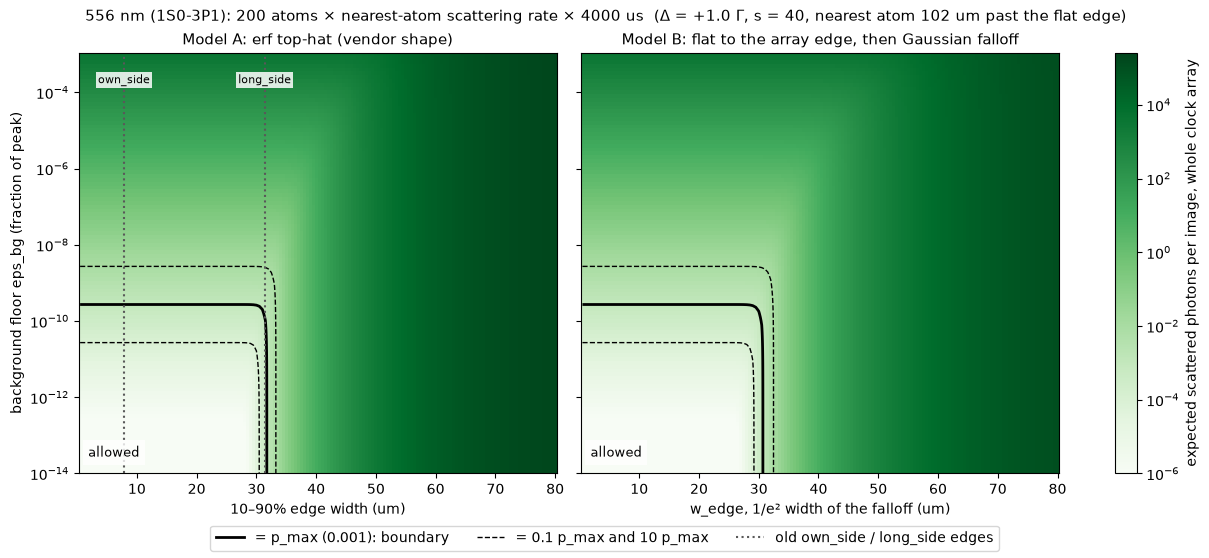

In [28]:
gap_now, gap_far = 45e-6, 100e-6           # region-to-region gap, m (now: nearest site at 67 um = 20 + 45 + 2 um)
x_nearest_far = x_nearest + (gap_far - gap_now)
edge_widths_far = np.linspace(0.5e-6, 80e-6, 160)
W_far, E_far = np.meshgrid(edge_widths_far, eps_grid)

key = "556"
L = lines[key]
e_max = intensity_budget(L)
A_max = brentq(lambda w: edge_A(x_nearest_far, w) - e_max, 1e-7, 1e-4)
B_max = brentq(lambda w: edge_B(x_nearest_far, w) - e_max, 1e-7, 1e-4)
search_far = {key: dict(P_A=photons_per_image(edge_A(x_nearest_far, W_far) + E_far, L),
                        P_B=photons_per_image(edge_B(x_nearest_far, W_far) + E_far, L),
                        eps_max=e_max, A_max=A_max, B_max=B_max)}

print(f"{L['name']}, gap {gap_far*1e6:.0f} um: nearest atom {(x_nearest_far - x_flat_edge)*1e6:.0f} um past the flat edge")
print(f"    with no background:          model A needs a 10-90% edge < {A_max*1e6:.1f} um (was {search[key]['A_max']*1e6:.1f}); "
      f"model B needs w_edge < {B_max*1e6:.1f} um (was {search[key]['B_max']*1e6:.1f})")
print(f"    with a perfectly sharp edge: background floor eps_bg < {e_max:.1e} (unchanged: a uniform floor doesn't depend on distance)")
for case in ("own_side", "long_side"):
    f_near = edge_A(x_nearest_far, 2.563*tophat_edges(case)[1])
    print(f"    {case} edge ({2.563*tophat_edges(case)[1]*1e6:.1f} um): designed edge at the nearest atom = {f_near:.1e} of peak "
          f"-> {'within' if f_near < e_max else 'over'} the budget")

plot_search(key, results=search_far, x_near=x_nearest_far, widths=edge_widths_far)

## 556 nm: phase-mask top-hat, then a knife edge (100 μm gap)

The 556 nm top-hat from the phase mask is formed in a plane that is imaged onto the atoms. A straight knife edge (along y) in that plane blocks everything beyond $x_k$, the side facing the clock array. The relay from the knife plane to the atoms has a hard aperture of numerical aperture NA. For coherent light and a straight edge this is a 1D problem: the field at the atoms is the cut field smoothed by the relay's amplitude point-spread function along x,
$$E(x_0) = \int_{-\infty}^{x_k} g(x')\, h(x_0 - x')\, dx', \qquad h(u) = \frac{\sin(k\,\mathrm{NA}\,u)}{\pi u},$$
where $g$ is the top-hat field ($\sqrt{\text{model A intensity}}$, flat phase) and $k = 2\pi/\lambda$. For a uniform field this reduces to the textbook knife-edge result $E = \tfrac12 + \mathrm{Si}(k\,\mathrm{NA}\,(x_k - x_0))/\pi$, which the code checks against. Far into the shadow the intensity falls only as $1/(\pi k\,\mathrm{NA}\,d)^2$, with fringes.

Assumptions:
- geometry: the 100 μm gap from the section above, so the nearest clock column is at 122 μm
- the knife plane is imaged 1:1 onto the atoms (positions are in atom-plane units), the relay aperture is hard-edged, and the clock atoms sit near y = 0, deep inside the 160 μm flat region in y
- the background leakage `eps_bg` originates before the knife: it is cut by the knife too, and adds to the top-hat's intensity (separate light, no interference)
- the fringes in the shadow move with sub-μm changes in alignment, so the clock-atom intensity is taken as the worst point within one fringe around the nearest atom (the envelope), not a lucky dark fringe
- imaging uniformity: the knife's ringing must keep every imaging column within `uniformity_tol` (10%) of the center

Swept: the knife position (20 μm up to just before the clock array), the relay NA (0.05–0.5), the top-hat's 10–90% edge width (0.5–80 μm), and the background. For each NA the summary gives the range of edge widths that works, with and without the knife; the lower limit comes from the relay, since an edge sharper than it can resolve picks up the relay's own diffraction tail.

Figures: (1) a check of the numerics against the exact knife-edge result, plus the widest working edge at one NA, with and without the knife; (2) photons per image vs top-hat edge width and knife position for four NA values, with upstream background blocked; (3) the widest allowed edge width as a function of upstream background, with the knife at its best position for each edge. A narrow edge lets the knife sit close to the imaging array, where it blocks more background, so edge width and background trade off. The small steps in (3) are real: the fringe pattern moves with the knife, so individual fringe peaks pass across the atom one at a time.

In [ ]:
from scipy.special import sici
from scipy.integrate import cumulative_trapezoid

L556 = lines["556"]
lam_um = 2*pi*c/L556["t"].omega * 1e6       # 556 nm line wavelength, um
x_kp = np.arange(-300, 300, 0.01)             # knife-plane coordinate, um (imaged 1:1 onto the atoms)

def relay_kernel(u, NA):
    '''Amplitude point-spread function along x of a relay with a hard aperture NA (1D coherent low-pass; integrates to 1).'''
    kNA = 2*pi/lam_um * NA
    return kNA/pi * np.sinc(kNA*u/pi)

def knife_field(g, x0, NA):
    '''Field at atom position x0 (um) for field g (on x_kp) cut by a knife and relayed with aperture NA.
    Element i of the result = knife at x_kp[i] (light kept for x < knife); the last element = no knife.'''
    return cumulative_trapezoid(g * relay_kernel(x0 - x_kp, NA), x_kp, initial=0)

def tophat_field(edge_10_90):
    '''Model-A top-hat field in the knife plane: peak 1, flat phase, 10-90% edge width edge_10_90 (um).'''
    return np.sqrt(edge_A(x_kp*1e-6, edge_10_90*1e-6))

def knife_uniform(x0, xk, NA):
    '''Exact field at x0 for a uniform field cut at xk (textbook knife-edge result), for checking and for the background.'''
    return 0.5 - sici(2*pi/lam_um*NA*(x0 - xk))[0]/pi

# check the numerics against the exact knife-edge result (uniform field over the whole grid)
worst = 0
for NA in [0.05, 0.5]:
    cum = knife_field(np.ones_like(x_kp), 67.0, NA)
    for xk in [25.0, 45.0, 60.0]:
        i = np.searchsorted(x_kp, xk)
        exact = (sici(2*pi/lam_um*NA*(67.0 - x_kp[0]))[0] - sici(2*pi/lam_um*NA*(67.0 - x_kp[i]))[0])/pi
        worst = max(worst, abs(cum[i] - exact)/abs(exact))
print(f"lambda = {lam_um*1e3:.1f} nm; numerical vs exact knife-edge field at the clock atom: worst relative error {worst:.1e}")

In [ ]:
NA_values = [0.05, 0.1, 0.2, 0.5]
x_clock = x_nearest_far*1e6                         # nearest clock column for the 100 um gap, um (122)
edge_list = np.arange(0.5, 80.01, 0.5)              # 10-90% edge width of the top-hat, um
x_knife = np.arange(20, x_clock - 2 + 0.01, 0.25)   # knife positions between the flat edge and the clock array, um
i_knife = np.searchsorted(x_kp, x_knife)
imaging_cols = np.arange(-18, 18.1, 4)              # imaging-array columns along x, um
uniformity_tol = 0.10                               # allowed deviation of any imaging column from the center
bg_levels = [1e-8, 1e-6, 1e-4]                      # upstream background levels for the summary
e_max556 = intensity_budget(L556)

knife = {}    # per NA: T = clock-atom intensity (fraction of center), U = worst imaging-column deviation,
              #         T_none = clock-atom intensity with no knife, S = background factor (eps_bg multiplier)
for NA in NA_values:
    window = x_clock + np.linspace(-1, 1, 17) * lam_um/(4*NA)     # one intensity fringe around the atom
    T = np.zeros((edge_list.size, x_knife.size)); U = np.zeros_like(T); T_none = np.zeros(edge_list.size)
    for j, w in enumerate(edge_list):
        g = tophat_field(w)
        E_center = knife_field(g, 0.0, NA)
        I_center = E_center[i_knife]**2
        clock = np.array([knife_field(g, xw, NA) for xw in window])
        T[j] = (clock[:, i_knife]**2).max(axis=0) / I_center
        T_none[j] = (clock[:, -1]**2).max() / E_center[-1]**2
        cols = np.array([knife_field(g, xc, NA)[i_knife]**2 for xc in imaging_cols])
        U[j] = np.abs(cols / I_center - 1).max(axis=0)
    S = np.array([knife_uniform(window, xk, NA)**2 for xk in x_knife]).max(axis=1)
    works = (photons_per_image(T, L556) <= p_max) & (U <= uniformity_tol)       # (edge width, knife position)
    j_req = np.flatnonzero(works.any(axis=1)).max() if works.any() else None    # widest edge that works with a knife
    # largest upstream eps_bg allowed at each (edge, knife), and the best knife position for each edge width
    tol = np.where(works, (e_max556 - T) / S[None, :], np.nan)
    rows = works.any(axis=1)
    tol_best = np.full(edge_list.size, np.nan); k_best = np.zeros(edge_list.size, dtype=int)
    tol_best[rows] = np.nanmax(tol[rows], axis=1); k_best[rows] = np.nanargmax(tol[rows], axis=1)
    knife[NA] = dict(T=T, U=U, T_none=T_none, S=S, works=works, j_req=j_req, tol_best=tol_best, k_best=k_best)

print(f"556 nm, {gap_far*1e6:.0f} um gap (nearest clock atom at {x_clock:.0f} um): budget eps_max = {e_max556:.2e} of peak")
for NA in NA_values:
    r = knife[NA]
    none_ok = photons_per_image(r["T_none"], L556) <= p_max
    print(f"NA {NA}:")
    print(f"    no knife:   10-90% edge {edge_list[none_ok].min():.1f}-{edge_list[none_ok].max():.1f} um works" if none_ok.any()
          else "    no knife:   no edge width works")
    if r["j_req"] is None:
        print("    with knife: no edge width works")
        continue
    j = r["j_req"]; ok_k = x_knife[r["works"][j]]
    print(f"    with knife: 10-90% edge {edge_list[r['works'].any(axis=1)].min():.1f}-{edge_list[j]:.1f} um works; "
          f"the widest needs the knife at {ok_k.min():.1f}-{ok_k.max():.1f} um and almost no background")
    for bg in bg_levels:                     # widest edge that still works with this much upstream background
        ok = np.flatnonzero(r["tol_best"] >= bg)
        print(f"    upstream eps_bg = {bg:.0e}: edge <= {edge_list[ok.max()]:.1f} um (knife at {x_knife[r['k_best'][ok.max()]]:.1f} um)"
              if ok.size else f"    upstream eps_bg = {bg:.0e}: no edge width works")

In [ ]:
# example: the widest edge that works at NA_ex, with and without the knife; plus a check of the numerics
NA_ex = next(NA for NA in [0.2] + NA_values if knife[NA]["j_req"] is not None)
r_ex = knife[NA_ex]; j_ex = r_ex["j_req"]; w_ex = edge_list[j_ex]
P_ex = photons_per_image(r_ex["T"][j_ex], L556)
k_ex = np.argmin(np.where(r_ex["works"][j_ex], P_ex, np.inf))      # knife position with the most margin
xk_ex, i_ex = x_knife[k_ex], i_knife[k_ex]
x_prof = np.linspace(-40, x_clock + 45, 801)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")

cut_uniform = np.where(x_kp < x_kp[i_ex], 1.0, 0.0)
I_num = np.array([knife_field(cut_uniform, x0, NA_ex)[-1]**2 for x0 in x_prof])
ax0.semilogy(x_prof, knife_uniform(x_prof, x_kp[i_ex], NA_ex)**2, color="k", lw=2, label="exact (sine-integral formula)")
ax0.semilogy(x_prof, I_num, color="tab:green", lw=1, ls="--", label="numerical (this code)")
d = np.clip(x_prof - xk_ex, 1e-9, None)
ax0.semilogy(x_prof[x_prof > xk_ex + 2], (1/(pi*2*pi/lam_um*NA_ex*d)**2)[x_prof > xk_ex + 2], color="0.5", lw=1, ls=":",
             label="envelope 1/(π k NA d)²")
ax0.set_title(f"Check: knife edge on a uniform field (NA = {NA_ex}, knife at {xk_ex:.1f} um)", fontsize=10)

E = np.array([knife_field(tophat_field(w_ex), x0, NA_ex)[[i_ex, -1]] for x0 in x_prof])
ax1.semilogy(x_prof, E[:, 1]**2, color="0.6", lw=1.2, label=f"edge {w_ex:.1f} um, no knife")
ax1.semilogy(x_prof, E[:, 0]**2, color="tab:green", lw=1.8, label=f"edge {w_ex:.1f} um, knife at {xk_ex:.1f} um")
ax1.axhline(e_max556, color="k", lw=1, ls=":", label=f"budget at the nearest atom ({e_max556:.1e})")
ax1.set_title(f"Widest working 556 nm top-hat edge at NA = {NA_ex}: {w_ex:.1f} um (10–90%)", fontsize=10)

for ax in (ax0, ax1):
    ax.axvspan(-20, 20, color="0.85", lw=0)                                   # imaging array (flat region)
    ax.axvspan(x_clock - 2, x_clock + 38, color="tab:green", alpha=0.12, lw=0) # clock array
    ax.axvline(xk_ex, color="k", lw=1)
    ax.text(xk_ex, 8, "knife ", fontsize=8, ha="right", va="center")
    ax.text(0, 8, "imaging array", fontsize=8, ha="center", va="center")
    ax.text(x_clock + 18, 8, "clock array", fontsize=8, ha="center", va="center")
    ax.set_ylim(1e-15, 40); ax.set_xlabel("x (um)"); ax.legend(fontsize=8, loc="lower left")
ax0.set_ylabel("intensity (fraction of the flat top)")
plt.show()

In [ ]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, len(NA_values), figsize=(15, 5), sharey=True, layout="constrained")
P_all = {NA: photons_per_image(knife[NA]["T"], L556) for NA in NA_values}
norm = LogNorm(1e-6, max(P.max() for P in P_all.values()))
for ax, NA in zip(axes, NA_values):
    r, P = knife[NA], P_all[NA]
    mesh = ax.pcolormesh(edge_list, x_knife, P.T, norm=norm, cmap=L556["cmap"], shading="auto")
    ax.contour(edge_list, x_knife, P.T, levels=[p_max], colors="k", linewidths=2)
    ax.contourf(edge_list, x_knife, (r["U"] > uniformity_tol).T.astype(float), levels=[0.5, 1.5],
                colors="none", hatches=["////"])
    no_knife_ok = photons_per_image(r["T_none"], L556) <= p_max
    if no_knife_ok.any():                                     # widest edge that works without a knife
        ax.axvline(edge_list[no_knife_ok].max(), color="k", ls=":", lw=1.5)
    req = f"edge ≤ {edge_list[r['j_req']]:.1f} um" if r["j_req"] is not None else "nothing works"
    ax.set_title(f"NA = {NA}: {req}", fontsize=11); ax.set_xlabel("top-hat 10–90% edge width (um)")
axes[0].set_ylabel("knife position x_k (um)")
fig.colorbar(mesh, ax=axes, label="expected scattered photons per image, whole clock array")
fig.legend(handles=[Line2D([], [], color="k", lw=2, label=f"= p_max ({p_max:g}): boundary (allowed = light region inside it)"),
                    Patch(facecolor="none", hatch="////", edgecolor="k", label=f"imaging-array ringing > {uniformity_tol:.0%}"),
                    Line2D([], [], color="k", ls=":", lw=1.5, label="widest edge that works with no knife")],
           loc="outside lower center", ncol=3)
fig.suptitle(f"556 nm top-hat + knife edge, {gap_far*1e6:.0f} um gap: photons scattered per image vs edge width and knife position\n"
             f"(upstream background blocked, Δ_clock = {L556['Delta']/L556['Gamma']:+.0f} Γ, s = {L556['s']}, nearest atom at {x_clock:.0f} um)",
             fontsize=11)
plt.show()

In [ ]:
# required edge width vs upstream background: for each edge width, the largest upstream eps_bg allowed with the knife
# at its best position (the top-hat's own tail, the knife's diffraction, and imaging uniformity all included)
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
greens = plt.cm.Greens(np.linspace(0.45, 0.95, len(NA_values)))
for NA, col in zip(NA_values, greens):
    ax.semilogy(edge_list, knife[NA]["tol_best"], color=col, lw=2.2, label=f"NA = {NA}, knife at its best position")
w_none = max(edge_list[photons_per_image(knife[NA]["T_none"], L556) <= p_max].max() for NA in NA_values)
ax.hlines(e_max556, edge_list[0], w_none, color="k", ls="--", lw=1.2, label=f"no knife: {e_max556:.1e} (edges up to {w_none:.1f} um)")
ax.set_xlabel("top-hat 10–90% edge width (um)"); ax.set_ylabel("largest allowed upstream background eps_bg")
ax.set_title(f"Required edge width vs background (556 nm, {gap_far*1e6:.0f} um gap, nearest atom at {x_clock:.0f} um)\n"
             "pick your background level on the y-axis and read off the widest edge each NA allows", fontsize=10)
ax.legend(fontsize=9, loc="lower left"); ax.grid(alpha=0.3, which="both")
plt.show()